# 03 - Model Training

This notebook trains and compares multiple regression models for used car resale price prediction. It uses the same production modules that power the command-line training workflow, avoiding notebook-only logic.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import Pipeline

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.data_preprocessing import prepare_model_data
from src.evaluate import build_model_comparison_table
from src.train import (
    build_model_registry,
    evaluate_pipeline,
    save_training_artifacts,
    tune_model,
)
from src.utils import RANDOM_STATE, load_raw_data

sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.max_columns", 100)

## Prepare Training Data

In [2]:
raw_data = load_raw_data()
features, target, preprocessor = prepare_model_data(raw_data)

features_train, features_test, target_train, target_test = train_test_split(
    features,
    target,
    test_size=0.2,
    random_state=RANDOM_STATE,
)

print(f"Training rows: {features_train.shape[0]:,}")
print(f"Test rows: {features_test.shape[0]:,}")
print(f"Feature count before preprocessing: {features_train.shape[1]:,}")
display(features_train.head())

Training rows: 239
Test rows: 60
Feature count before preprocessing: 15


,year,present_price,driven_km,fuel_type,seller_type,transmission,owner,car_age,km_per_year,brand,is_luxury_brand,vehicle_age_bucket,price_segment,log_present_price,log_driven_km
6,2015,8.12,18796.0,Petrol,Dealer,Manual,0,11,1708.727273,ciaz,0,9-12 years,premium,2.210470,9.841453
183,2008,0.58,1900.0,Petrol,Individual,Automatic,0,18,105.555556,suzuki,0,12+ years,budget,0.457425,7.550135
185,2013,0.51,32000.0,Petrol,Individual,Manual,0,13,2461.538462,honda,0,12+ years,budget,0.412110,10.373522
146,2010,0.94,45000.0,Petrol,Individual,Manual,0,16,2812.500000,bajaj,0,12+ years,budget,0.662688,10.714440
30,2011,4.89,54200.0,Petrol,Dealer,Manual,0,15,3613.333333,ritz,0,12+ years,mid_market,1.773256,10.900455


**Modeling note:** The train-test split is held constant across all models, and every model receives the same preprocessing pipeline. This creates a fair comparison and prevents hidden preprocessing differences from driving results.

## Baseline Model Registry

In [3]:
models = build_model_registry()
pd.DataFrame({"model": list(models.keys())})

,model
0,Linear Regression
1,Decision Tree
2,Random Forest
3,Gradient Boosting
4,XGBoost
5,CatBoost
6,LightGBM


**Modeling note:** The registry includes simple, interpretable baselines and stronger tree-boosting methods. Optional libraries such as XGBoost, CatBoost, and LightGBM are included when installed.

## 5-Fold Cross-Validation Baseline Comparison

In [4]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
baseline_results = []

for model_name, model in models.items():
    pipeline = Pipeline(
        steps=[
            ("preprocessor", clone(preprocessor)),
            ("model", model),
        ]
    )
    result = evaluate_pipeline(
        model_name,
        pipeline,
        features_train,
        features_test,
        target_train,
        target_test,
        cv,
    )
    baseline_results.append(result)

baseline_comparison = build_model_comparison_table(
    [
        {
            "model": result.model_name,
            **result.test_metrics,
            "cv_rmse_mean": result.cv_rmse_mean,
            "cv_rmse_std": result.cv_rmse_std,
        }
        for result in baseline_results
    ]
)
display(baseline_comparison)

,model,r2,mae,rmse,mape,median_absolute_error,explained_variance,cv_rmse_mean,cv_rmse_std
0,CatBoost,0.898697,0.692042,1.174788,25.744631,0.392861,0.903563,0.852612,0.252316
1,LightGBM,0.852462,0.900738,1.417752,40.986766,0.442979,0.866451,1.022253,0.270480
2,XGBoost,0.733281,0.873739,1.906227,29.122172,0.252073,0.748266,0.768609,0.197650
3,Gradient Boosting,0.723884,0.920962,1.939518,29.377871,0.273801,0.748765,0.788327,0.164181
4,Random Forest,0.697604,0.957822,2.029718,30.372361,0.378592,0.716926,0.772307,0.212343
5,Linear Regression,0.695304,1.203092,2.037423,129.573272,0.796331,0.706321,1.178147,0.177060
6,Decision Tree,0.582147,1.050083,2.385942,36.795687,0.250000,0.610007,0.925225,0.175045


**Modeling note:** Cross-validation measures stability across folds, while the holdout test set estimates generalization on unseen listings. A production candidate should perform well on both, not just one.

## Baseline Comparison Plot

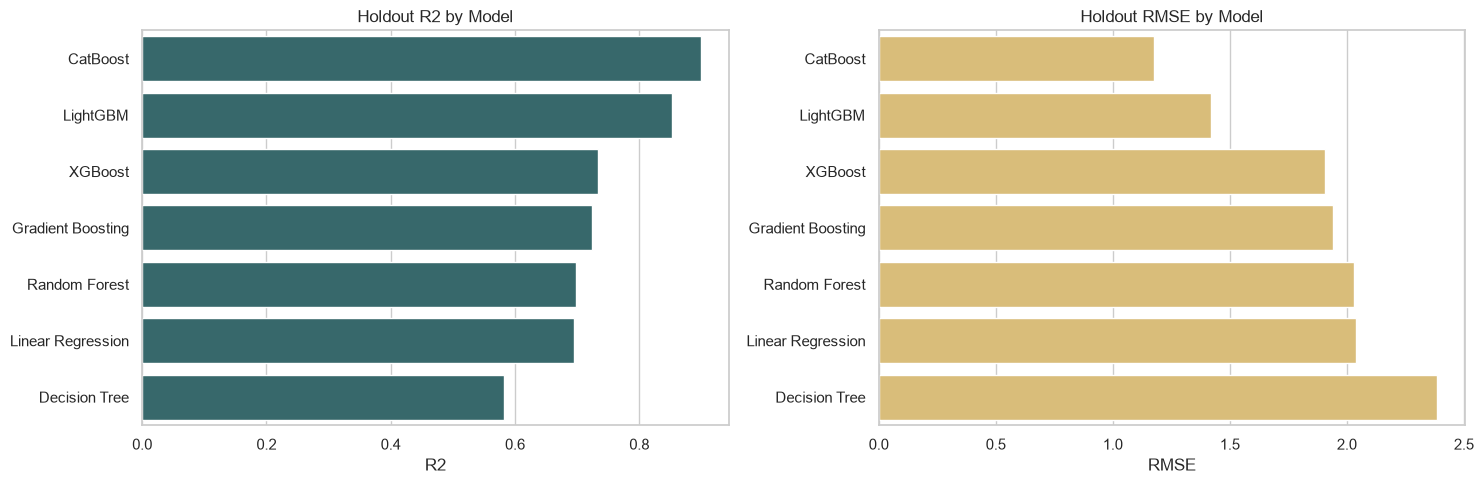

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=baseline_comparison, x="r2", y="model", ax=axes[0], color="#2f6f73")
axes[0].set_title("Holdout R2 by Model")
axes[0].set_xlabel("R2")
axes[0].set_ylabel("")

sns.barplot(data=baseline_comparison, x="rmse", y="model", ax=axes[1], color="#e9c46a")
axes[1].set_title("Holdout RMSE by Model")
axes[1].set_xlabel("RMSE")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

**Business insight:** RMSE is useful when large pricing mistakes are costly, while MAE is easier to explain operationally as the average absolute pricing miss. R2 helps compare variance explained across model families.

## Hyperparameter Tuning

In [6]:
top_model_names = baseline_comparison.head(3)["model"].tolist()
tuned_results = []

for model_name in top_model_names:
    baseline = next(result for result in baseline_results if result.model_name == model_name)
    tuned_pipeline = tune_model(
        model_name,
        baseline.estimator,
        features_train,
        target_train,
        cv,
    )
    tuned_result = evaluate_pipeline(
        f"{model_name} Tuned",
        tuned_pipeline,
        features_train,
        features_test,
        target_train,
        target_test,
        cv,
    )
    tuned_results.append(tuned_result)

tuned_comparison = build_model_comparison_table(
    [
        {
            "model": result.model_name,
            **result.test_metrics,
            "cv_rmse_mean": result.cv_rmse_mean,
            "cv_rmse_std": result.cv_rmse_std,
        }
        for result in tuned_results
    ]
)
display(tuned_comparison)

,model,r2,mae,rmse,mape,median_absolute_error,explained_variance,cv_rmse_mean,cv_rmse_std
0,CatBoost Tuned,0.871467,0.707180,1.323291,24.934250,0.329245,0.879675,0.781912,0.146776
1,LightGBM Tuned,0.853098,0.923584,1.414693,41.994631,0.567949,0.868190,1.003101,0.238321
2,XGBoost Tuned,0.835006,0.758303,1.499277,23.890338,0.279103,0.845869,0.740026,0.166024


**Modeling note:** Tuning is limited to the strongest baseline candidates to control compute cost. This mirrors practical ML work where search budgets are allocated to promising model families rather than every possible estimator.

## Final Model Ranking

In [7]:
all_results = baseline_results + tuned_results
final_comparison = build_model_comparison_table(
    [
        {
            "model": result.model_name,
            **result.test_metrics,
            "cv_rmse_mean": result.cv_rmse_mean,
            "cv_rmse_std": result.cv_rmse_std,
        }
        for result in all_results
    ]
)

best_model_name = final_comparison.loc[0, "model"]
best_result = next(result for result in all_results if result.model_name == best_model_name)

display(final_comparison)
print(f"Selected best model: {best_result.model_name}")

,model,r2,mae,rmse,mape,median_absolute_error,explained_variance,cv_rmse_mean,cv_rmse_std
0,CatBoost,0.898697,0.692042,1.174788,25.744631,0.392861,0.903563,0.852612,0.252316
1,CatBoost Tuned,0.871467,0.707180,1.323291,24.934250,0.329245,0.879675,0.781912,0.146776
2,LightGBM Tuned,0.853098,0.923584,1.414693,41.994631,0.567949,0.868190,1.003101,0.238321
3,LightGBM,0.852462,0.900738,1.417752,40.986766,0.442979,0.866451,1.022253,0.270480
4,XGBoost Tuned,0.835006,0.758303,1.499277,23.890338,0.279103,0.845869,0.740026,0.166024
5,XGBoost,0.733281,0.873739,1.906227,29.122172,0.252073,0.748266,0.768609,0.197650
6,Gradient Boosting,0.723884,0.920962,1.939518,29.377871,0.273801,0.748765,0.788327,0.164181
7,Random Forest,0.697604,0.957822,2.029718,30.372361,0.378592,0.716926,0.772307,0.212343
8,Linear Regression,0.695304,1.203092,2.037423,129.573272,0.796331,0.706321,1.178147,0.177060
9,Decision Tree,0.582147,1.050083,2.385942,36.795687,0.250000,0.610007,0.925225,0.175045


Selected best model: CatBoost


**Business insight:** The selected model balances predictive accuracy and validation stability. For marketplace pricing, a slightly less complex but stable model can be preferable when prediction consistency matters across seller segments.

## Save Production Artifacts

In [8]:
save_training_artifacts(best_result, final_comparison, features_train, target_train)
print("Saved best model, fitted preprocessor, metrics, and feature importance artifacts.")

Saved best model, fitted preprocessor, metrics, and feature importance artifacts.


## Training Takeaways

- Every model is evaluated through the same preprocessing pipeline.
- 5-fold cross-validation is used to estimate model stability.
- Tree-based ensemble methods are expected to perform strongly because used-car pricing is nonlinear.
- The final model and preprocessing pipeline are saved separately for API and Streamlit deployment.
- Model metrics and feature importance artifacts are saved for reporting and monitoring.